# Aula 12 – Métricas para regressão e comparação entre modelos

## Versão do aluno

### Objetivo da aula
Avaliar e comparar modelos de regressão utilizando métricas quantitativas e análise de resíduos.

### Instruções
Complete as células indicadas e registre suas interpretações ao longo da atividade.  
Use os gráficos para apoiar sua análise técnica.


## 1. Importação das bibliotecas

Importe as bibliotecas necessárias para:
- leitura e manipulação da base;
- visualização;
- pré-processamento;
- treino de modelos;
- cálculo das métricas de regressão.


In [1]:
# Complete aqui
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)

print('Bibliotecas importadas com sucesso!')

Bibliotecas importadas com sucesso!


## 2. Leitura da base

Leia o arquivo `dados_aula12_metricas_regressao.csv` e exiba as primeiras linhas.


In [2]:
# Complete aqui
df = pd.read_csv('dados_aula12_metricas_regressao.csv')
df.head()

,id_registro,linha,turno,produto,temperatura_c,pressao_bar,vibracao_mm_s,abertura_valvula_pct,consumo_energia_kwh,tempo_resposta_s,erro_vazao_pct,leituras_invalidas,horas_operacao_bomba,vazao_real_l_min
0,REG12_0001,Linha_A,Manhã,Base,47.07,4.29,2.37,44.61,19.36,2.12,3.46,3,503.4,60.67
1,REG12_0002,Linha_A,Manhã,Solvente,42.93,3.82,1.77,49.26,21.77,1.75,4.70,2,253.0,48.19
2,REG12_0003,Linha_B,Tarde,Acido,47.22,4.19,1.63,74.98,20.09,2.46,2.11,3,361.1,79.25
3,REG12_0004,Linha_A,Tarde,Solvente,57.47,3.38,1.83,75.58,19.13,2.86,3.68,2,379.8,67.94
4,REG12_0005,Linha_B,Manhã,Acido,41.55,3.92,2.16,54.53,23.95,1.22,1.88,2,265.2,68.51


## 3. Inspeção inicial da base

Verifique:
- dimensão da base;
- tipos de dados;
- valores faltantes;
- duplicatas.


In [3]:
# Complete aqui
print('Dimensão da base:', df.shape)
print('\nTipos de dados:')
print(df.dtypes)
print('\nValores faltantes:')
print(df.isna().sum())
print('\nDuplicatas:', df.duplicated().sum())

Dimensão da base: (370, 14)

Tipos de dados:
id_registro              object
linha                    object
turno                    object
produto                  object
temperatura_c           float64
pressao_bar             float64
vibracao_mm_s           float64
abertura_valvula_pct    float64
consumo_energia_kwh     float64
tempo_resposta_s        float64
erro_vazao_pct          float64
leituras_invalidas        int64
horas_operacao_bomba    float64
vazao_real_l_min        float64
dtype: object

Valores faltantes:
id_registro             0
linha                   0
turno                   0
produto                 8
temperatura_c           8
pressao_bar             8
vibracao_mm_s           0
abertura_valvula_pct    0
consumo_energia_kwh     0
tempo_resposta_s        8
erro_vazao_pct          0
leituras_invalidas      0
horas_operacao_bomba    0
vazao_real_l_min        0
dtype: int64

Duplicatas: 10


**Registro do aluno:**  
- dimensão da base: 370 x 14
- tipos de dados: object, float64, int64
- valores faltantes: 32
- duplicatas: 10

## 4. Limpeza básica

Remova as duplicatas da base.


In [4]:
# Complete aqui
df = df.drop_duplicates().copy()
print(df.shape)

(360, 14)


## 5. Definição de X e y

Separe:
- `X`: variáveis preditoras;
- `y`: variável-alvo contínua `vazao_real_l_min`.

**Pergunta:**  
Por que `id_registro` não deve ser utilizado como variável preditora?


In [5]:
# Complete aqui
X = df.drop(columns=['id_registro', 'vazao_real_l_min'])
y = df['vazao_real_l_min']

print(X.shape)
print(y.shape)

(360, 12)
(360,)


**Resposta do aluno:**  


## 6. Divisão em treino e teste

Divida a base em treino e teste.


In [6]:
# Complete aqui
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.25, random_state = 42
)

print('Treino:', X_train.shape, y_train.shape)
print('Teste:', X_test.shape, y_test.shape)

Treino: (270, 12) (270,)
Teste: (90, 12) (90,)


## 7. Pré-processamento com pipeline

Monte um pipeline com:
- imputação da mediana + padronização para numéricas;
- imputação da moda + one-hot encoding para categóricas.


In [7]:
# Complete aqui
colunas_numericas = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
colunas_categoricas = X.select_dtypes(include=['object']).columns.tolist()

transformador_numerico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

transformador_categorico = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessador = ColumnTransformer(transformers=[
    ('num', transformador_numerico, colunas_numericas),
    ('cat', transformador_categorico, colunas_categoricas)
])

## 8. Criação de dois modelos para comparação

Crie:
- um modelo de Regressão Linear;
- um modelo de Árvore de Decisão Regressora.


In [8]:
# Complete aqui
modelo_linear = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', LinearRegression())
])

modelo_arvore = Pipeline(steps=[
    ('preprocessador', preprocessador),
    ('modelo', DecisionTreeRegressor(max_depth=5, random_state = 42))
])

## 9. Treino dos modelos

Treine os dois modelos com os dados de treino.


In [9]:
# Complete aqui
modelo_linear.fit(X_train, y_train)
modelo_arvore.fit(X_train, y_train)

print('Modelos treinados com sucesso.')

Modelos treinados com sucesso.


## 10. Predições no conjunto de teste

Gere as previsões dos dois modelos.


In [10]:
# Complete aqui
pred_linear = modelo_linear.predict(X_test)
pred_arvore = modelo_arvore.predict(X_test)

## 11. Cálculo das métricas de regressão

Calcule:
- MAE
- MSE
- RMSE
- R²

Depois, monte uma tabela comparativa.


In [11]:
# Complete aqui
def calcular_metricas(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_real, y_pred)
    return mae, mse, rmse, r2

metricas = pd.DataFrame({
    'Modelo': ['Regressão Linear', 'Árvore de Decisão'],
    'MAE': [
      calcular_metricas(y_test, pred_linear)[0],
      calcular_metricas(y_test, pred_arvore)[0]
    ],
    'MSE': [
      calcular_metricas(y_test, pred_linear)[1],
      calcular_metricas(y_test, pred_arvore)[1]
    ],
    'RMSE': [
      calcular_metricas(y_test, pred_linear)[2],
      calcular_metricas(y_test, pred_arvore)[2]
    ],
    'R2': [
      calcular_metricas(y_test, pred_linear)[3],
      calcular_metricas(y_test, pred_arvore)[3]
    ]
}).round(4)

metricas

,Modelo,MAE,MSE,RMSE,R2
0,Regressão Linear,4.8711,38.0696,6.1701,0.7284
1,Árvore de Decisão,7.5279,79.0082,8.8887,0.4362


## 12. Visualização comparativa das métricas

Crie gráficos para comparar:
- MAE
- MSE
- RMSE
- R²


In [12]:
# Complete aqui
metricas_plot = metricas.set_index('Modelo')

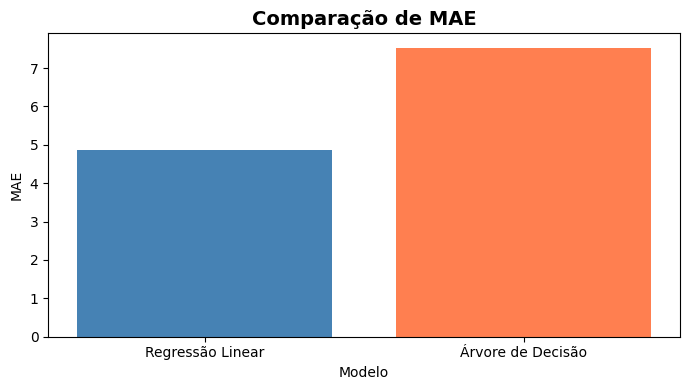

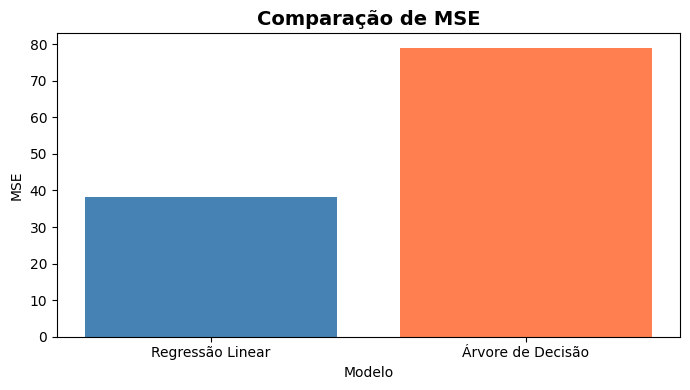

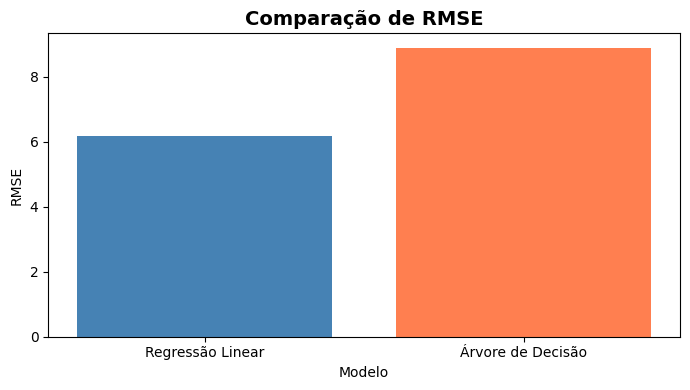

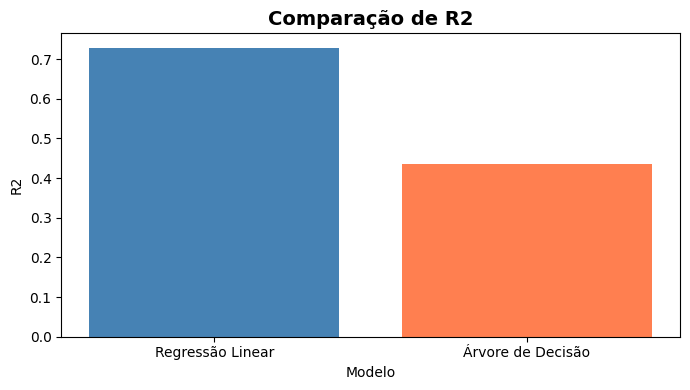

In [13]:
# Gere os gráficos aqui para MAE, MSE, RMSE e R²
for coluna in ['MAE', 'MSE', 'RMSE', 'R2']:
  plt.figure(figsize=(7, 4))
  plt.bar(metricas_plot.index, metricas_plot[coluna], color=['steelblue', 'coral'])
  plt.title(f'Comparação de {coluna}', fontsize=14, fontweight='bold')
  plt.ylabel(coluna)
  plt.xlabel('Modelo')
  plt.tight_layout()
  plt.show()

## 13. Observado x previsto

Crie gráficos comparando o valor real com o valor previsto para os dois modelos.


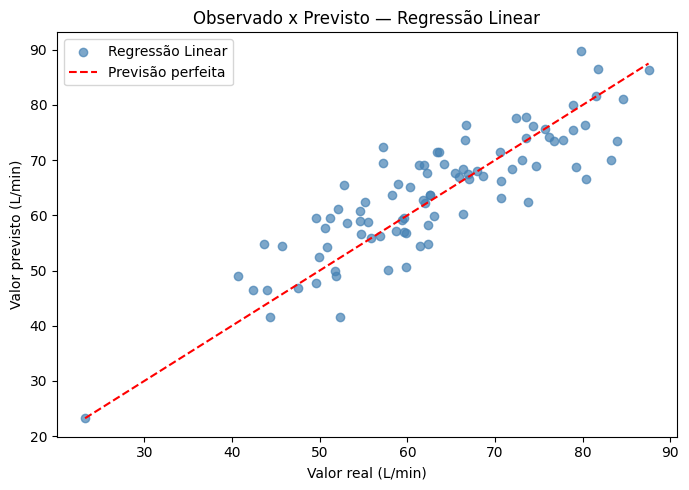

In [14]:
# Gere aqui o gráfico da Regressão Linear
plt.figure(figsize=(7, 5))
plt.scatter(y_test, pred_linear, alpha=0.7, label='Regressão Linear',
color='steelblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--', color='red', label='Previsão perfeita')
plt.xlabel('Valor real (L/min)')
plt.ylabel('Valor previsto (L/min)')
plt.title('Observado x Previsto — Regressão Linear')
plt.legend()
plt.tight_layout()
plt.show()

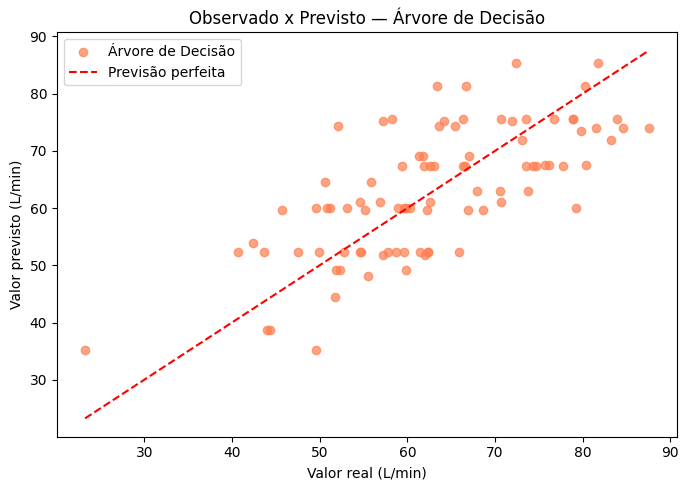

In [15]:
# Gere aqui o gráfico da Árvore de Decisão
plt.figure(figsize=(7, 5))
plt.scatter(y_test, pred_arvore, alpha=0.7, label='Árvore de Decisão',
color='coral')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--', color='red', label='Previsão perfeita')
plt.xlabel('Valor real (L/min)')
plt.ylabel('Valor previsto (L/min)')
plt.title('Observado x Previsto — Árvore de Decisão')
plt.legend()
plt.tight_layout()
plt.show()

## 14. Cálculo dos resíduos

Calcule os resíduos dos dois modelos.


In [16]:
# Complete aqui
residuos_linear = y_test - pred_linear
residuos_arvore = y_test - pred_arvore

pd.DataFrame({
    'residuos_linear': residuos_linear[:5],
    'residuos_arvore': residuos_arvore[:5]
})

,residuos_linear,residuos_arvore
224,-6.842435,-1.110500
42,-9.130310,-22.278889
285,1.796423,7.287143
302,-5.471761,-17.266087
56,-7.978403,-10.778889


## 15. Gráfico de resíduos

Faça os gráficos de resíduos para os dois modelos.


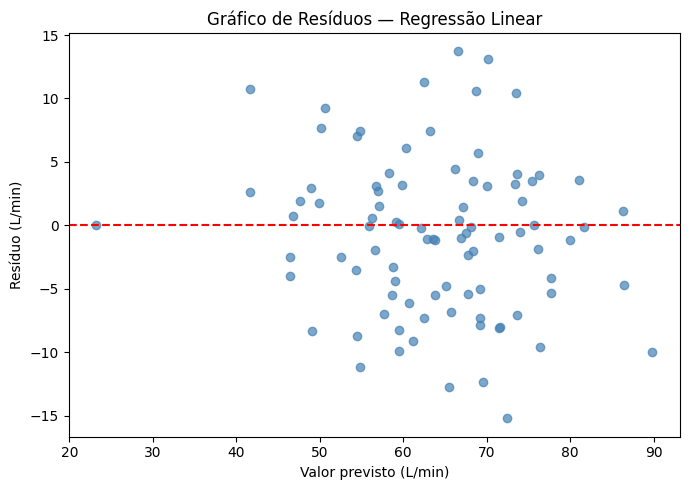

In [17]:
# Gere aqui o gráfico de resíduos da Regressão Linear
plt.figure(figsize=(7, 5))
plt.scatter(pred_linear, residuos_linear, alpha=0.7, color='steelblue')
plt.axhline(0, linestyle='--', color='red') # Linha do zero (resíduo ideal)
plt.xlabel('Valor previsto (L/min)')
plt.ylabel('Resíduo (L/min)')
plt.title('Gráfico de Resíduos — Regressão Linear')
plt.tight_layout()
plt.show()

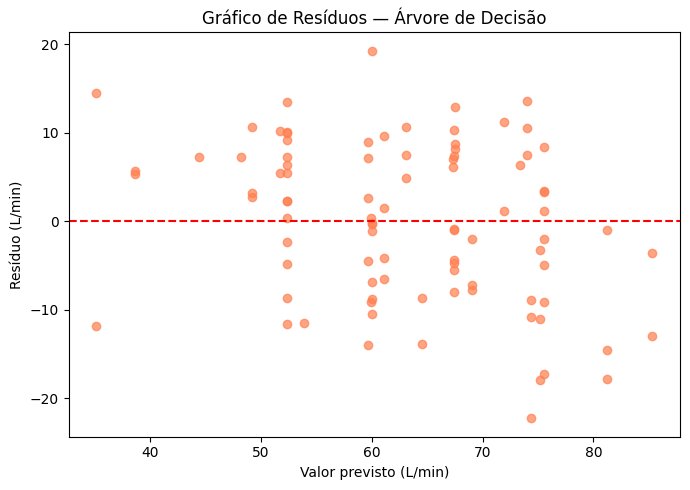

In [18]:
# Gere aqui o gráfico de resíduos da Árvore de Decisão
plt.figure(figsize=(7, 5))
plt.scatter(pred_arvore, residuos_arvore, alpha=0.7, color='coral')
plt.axhline(0, linestyle='--', color='red') # Linha do zero (resíduo ideal)
plt.xlabel('Valor previsto (L/min)')
plt.ylabel('Resíduo (L/min)')
plt.title('Gráfico de Resíduos — Árvore de Decisão')
plt.tight_layout()
plt.show()

## 16. Histograma dos resíduos

Crie histogramas para observar a distribuição dos resíduos.


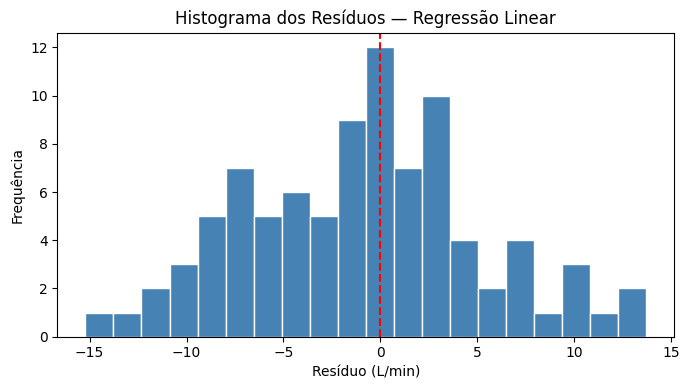

In [19]:
# Gere aqui o histograma dos resíduos da Regressão Linear
plt.figure(figsize=(7, 4))
plt.hist(residuos_linear, bins=20, color='steelblue', edgecolor='white')
plt.title('Histograma dos Resíduos — Regressão Linear')
plt.xlabel('Resíduo (L/min)')
plt.ylabel('Frequência')
plt.axvline(0, linestyle='--', color='red') # Linha de resíduo zero ideal
plt.tight_layout()
plt.show()

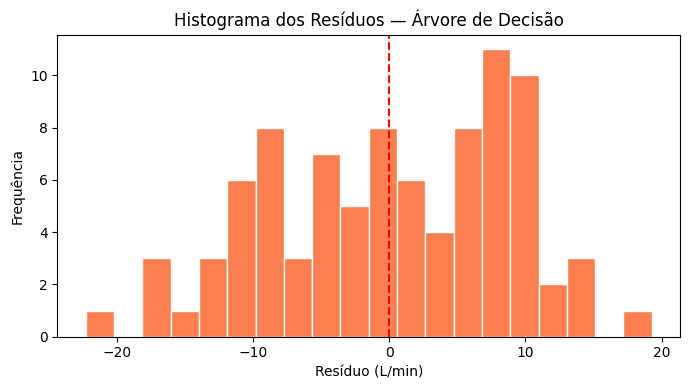

In [20]:
# Gere aqui o histograma dos resíduos da Árvore de Decisão
plt.figure(figsize=(7, 4))
plt.hist(residuos_arvore, bins=20, color='coral', edgecolor='white')
plt.title('Histograma dos Resíduos — Árvore de Decisão')
plt.xlabel('Resíduo (L/min)')
plt.ylabel('Frequência')
plt.axvline(0, linestyle='--', color='red')
plt.tight_layout()
plt.show()

## 17. Interpretação dos resultados

Escreva:
- qual modelo teve melhores métricas;
- qual modelo apresentou resíduos mais adequados;
- qual parece mais apropriado para o contexto industrial.


**Resposta do aluno:**  
- Melhor nas métricas:  Regressão Linear.
- Melhor nos resíduos:  Regressão Linear.
- Mais adequado ao contexto:  Regressão Linear.


## 18. Síntese interpretativa

Explique, com suas palavras, por que a comparação entre modelos não deve se basear em apenas uma única métrica.


**Resposta do aluno:**  
Muitas vezes a métrica do modelo não acaba sendo muito significativa para a empresa. O modelo pode ter um bom desempenho em algumas métricas, mas pode não ser tão vantajoso no custo.

## 19. Exportação dos resultados

Salve:
- a tabela de métricas;
- a tabela com resíduos e predições.


In [22]:
# Complete aqui
comparacao_pred = pd.DataFrame({
  'y_real': y_test.values,
  'pred_linear': pred_linear,
  'pred_arvore': pred_arvore,
  'residuo_linear': residuos_linear,
  'residuo_arvore': residuos_arvore
})

metricas.to_csv('metricas_regressao_aula12.csv', index = False)
comparacao_pred.to_csv('comparacao_predicoes_residuos_aula12.csv', index = False)

print('Arquivos exportados com sucesso.')

Arquivos exportados com sucesso.


## 20. Fechamento

Verifique se você:
- calculou e interpretou corretamente as métricas de regressão;
- analisou resíduos com coerência técnica;
- comparou modelos com base em evidências quantitativas;
- organizou o material analítico de forma clara.
